In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
from scipy.stats import ttest_ind, chi2_contingency, pearsonr
import statsmodels.api as sm
from statsmodels.formula.api import ols
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [6]:
data = pd.read_csv(r"C:\Users\srini\OneDrive\Desktop\Data analytics course\ML\Machine Learning\insurance\insurance.csv")
data.head(3)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.9240
1,18,male,33.77,1,no,southeast,1725.5523
2,28,male,33.00,3,no,southeast,4449.4620


In [7]:
data.shape

(1338, 7)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [9]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [10]:
print("Duplicate rows:", data.duplicated().sum())
data[data.duplicated(keep=False)]

Duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [11]:
data = data.drop_duplicates().reset_index(drop=True)

In [12]:
data.shape

(1337, 7)

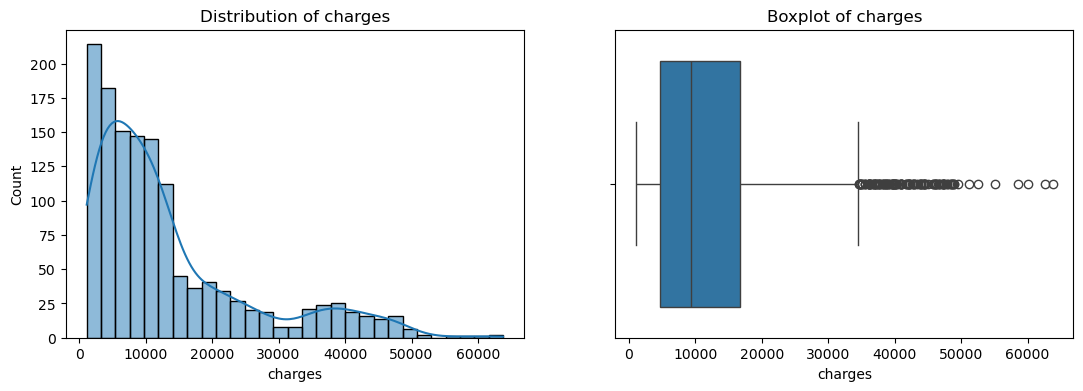

In [80]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data.charges, kde=True, ax=ax[0]); ax[0].set_title("Distribution of charges")
sns.boxplot(x=data.charges, ax=ax[1]); ax[1].set_title("Boxplot of charges")
plt.show()

In [14]:
Q1 = data.charges.quantile(0.25)
Q3 = data.charges.quantile(0.75)
IQR = Q3 - Q1
LE = Q1 - 1.5*IQR
HE = Q3 + 1.5*IQR
outliers = data[(data.charges < LE) | (data.charges > HE)]
print("Lower:", round(LE,2), " Upper:", round(HE,2), " Outliers:", len(outliers))
outliers.smoker.value_counts()

Lower: -13120.72  Upper: 34524.78  Outliers: 139


smoker
yes    136
no       3
Name: count, dtype: int64

# Almost all the outliers are smokers

In [17]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [16]:
for i in ['sex', 'smoker', 'region', 'children']:
    print(data[i].value_counts(), "\n")

sex
male      675
female    662
Name: count, dtype: int64 

smoker
no     1063
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64 

children
0    573
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64 



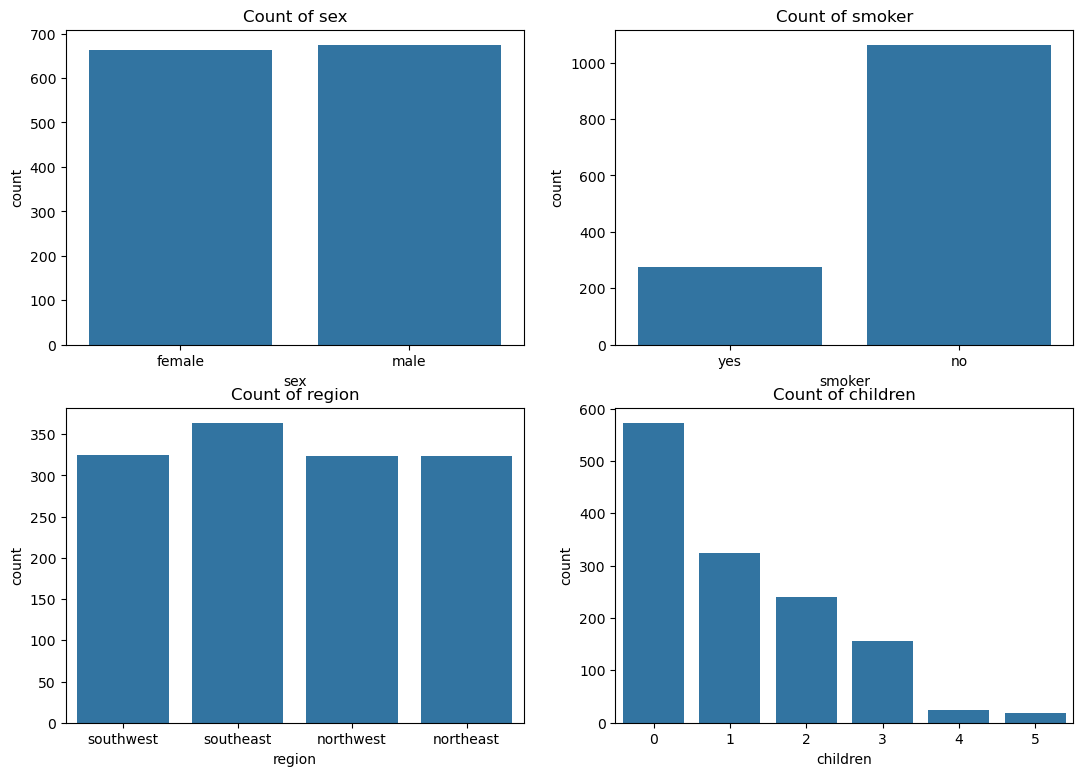

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, i in zip(ax.flat, ['sex', 'smoker', 'region', 'children']):
    sns.countplot(x=data[i], ax=a); a.set_title(f"Count of {i}")
plt.show()

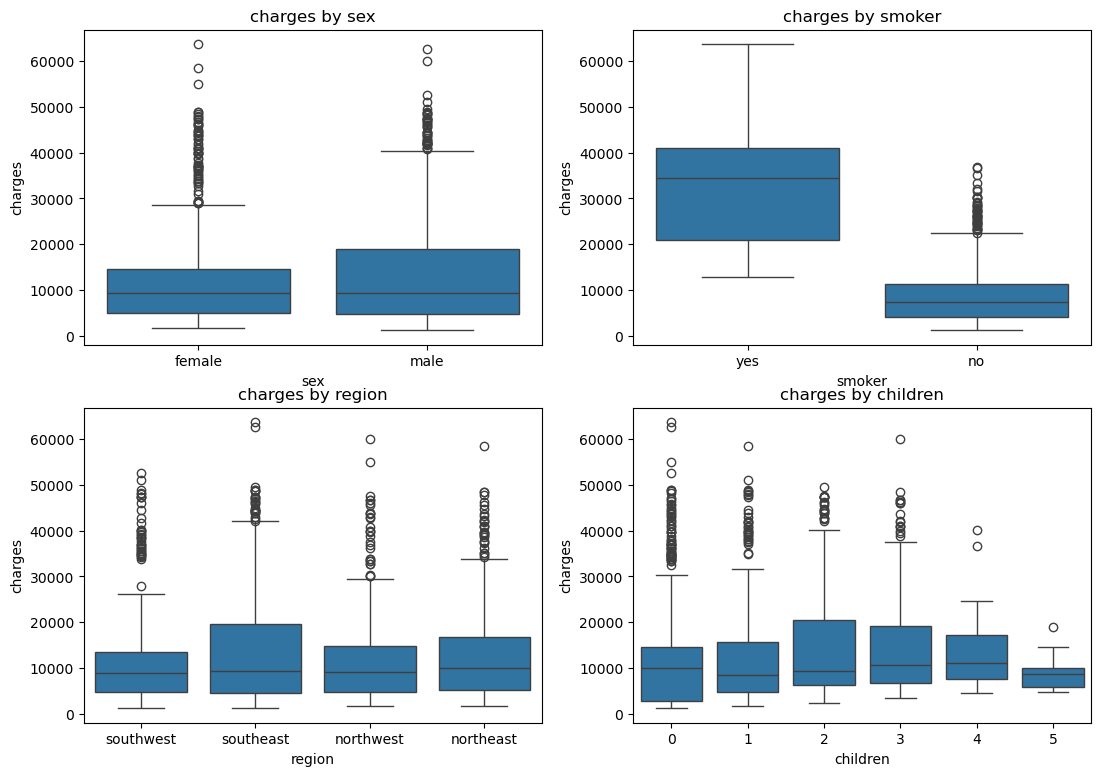

In [25]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, col in zip(ax.flat, ['sex', 'smoker', 'region', 'children']):
    sns.boxplot(x=col, y='charges', data=data, ax=a); a.set_title(f"charges by {col}")
plt.show()

In [26]:
for i in ['sex', 'smoker', 'region', 'children']:
    print(data.groupby(i)['charges'].mean().round(2), "\n")

sex
female    12569.58
male      13975.00
Name: charges, dtype: float64 

smoker
no      8440.66
yes    32050.23
Name: charges, dtype: float64 

region
northeast    13406.38
northwest    12450.84
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64 

children
0    12384.70
1    12731.17
2    15073.56
3    15355.32
4    13850.66
5     8786.04
Name: charges, dtype: float64 



# Statistical Analysis
## TTest for sex vs charges
### charges is continous
### sex is categorical with 2 levels
### smoker is categorical with 2 levels
### age and bmi are also continos

In [28]:
male = data[data.sex == 'male']['charges']
female = data[data.sex == 'female']['charges']
t_stat, p_val = ttest_ind(male, female)
print("t =", round(t_stat, 3), " p-value =", round(p_val, 4))
print("Good predictor" if p_val < 0.05 else "NOT a good predictor")

t = 2.124  p-value = 0.0338
Good predictor


## TTest for sex vs charges

In [29]:
smk = data[data.smoker == 'yes']['charges']
non = data[data.smoker == 'no']['charges']
t_stat, p_val = ttest_ind(smk, non)
print("t =", round(t_stat, 3), " p-value =", p_val)
print("Good predictor" if p_val < 0.05 else "NOT a good predictor")

t = 46.645  p-value = 1.4067220949376498e-282
Good predictor


# ANOVA Test
## region vs charges

In [30]:
model_region = ols("charges ~ C(region)", data=data).fit()
sm.stats.anova_lm(model_region)

,df,sum_sq,mean_sq,F,PR(>F)
C(region),3.0,1.281906e+09,4.273019e+08,2.92614,0.032763
Residual,1333.0,1.946569e+11,1.460292e+08,NaN,NaN


In [31]:
tukey = pairwise_tukeyhsd(endog=data.charges, groups=data.region, alpha=0.05)
print(tukey)

       Multiple Comparison of Means - Tukey HSD, FWER=0.05       
  group1    group2   meandiff  p-adj    lower      upper   reject
-----------------------------------------------------------------
northeast northwest  -955.5437 0.7457 -3397.7353  1486.648  False
northeast southeast  1329.0269 0.4746 -1045.1237 3703.1776  False
northeast southwest -1059.4471 0.6793 -3499.7595 1380.8652  False
northwest southeast  2284.5706 0.0643     -89.58 4658.7212  False
northwest southwest  -103.9035 0.9995 -2544.2158 2336.4088  False
southeast southwest -2388.4741 0.0477 -4760.6915  -16.2567   True
-----------------------------------------------------------------


## ANOVA for children vs charges

In [32]:
model_children = ols("charges ~ C(children)", data=data).fit()
sm.stats.anova_lm(model_children)

,df,sum_sq,mean_sq,F,PR(>F)
C(children),5.0,2.376795e+09,4.753591e+08,3.268734,0.006133
Residual,1331.0,1.935620e+11,1.454260e+08,NaN,NaN


# Correlation ; Continous vs Continous
## age and bmi vs charges

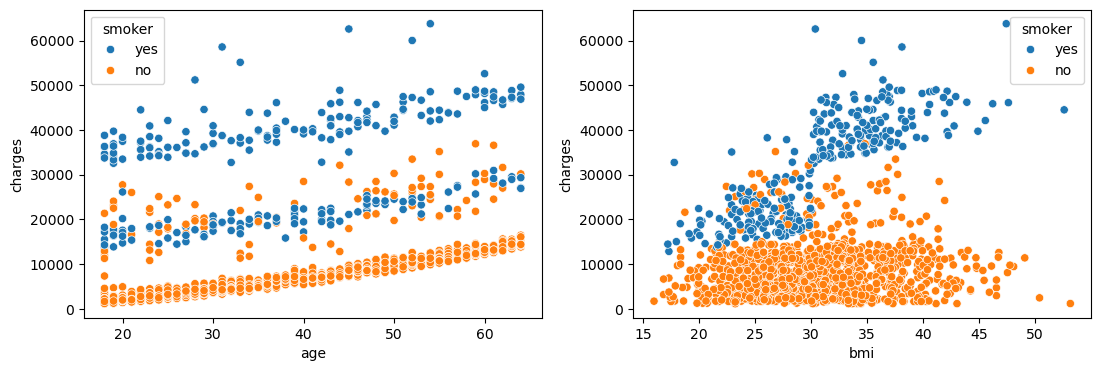

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(x='age', y='charges', hue='smoker', data=data, ax=ax[0])
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=data, ax=ax[1])
plt.show()

In [38]:
for i in ['age', 'bmi']:
    r, p = pearsonr(data[i], data.charges)
    print(f"{i:4s}: r = {r:.3f}, p-value = {p:.2e}")
data[['age', 'bmi', 'charges']].corr()

age : r = 0.298, p-value = 6.98e-29
bmi : r = 0.198, p-value = 2.47e-13


,age,bmi,charges
age,1.000000,0.109344,0.298308
bmi,0.109344,1.000000,0.198401
charges,0.298308,0.198401,1.000000


Both are positively correlated with charges

# Chi-square btw Smoker and Sex
## both are categorical

In [43]:
table = pd.crosstab(data.sex, data.smoker)
print(table, "\n")
chi2_stat, p_val, dof, expected = chi2_contingency(table)
print("chi2 =", round(chi2_stat, 3), " dof =", dof, " p-value =", round(p_val, 4))
print("Related" if p_val < 0.05 else "Independent")

smoker   no  yes
sex             
female  547  115
male    516  159 

chi2 = 7.469  dof = 1  p-value = 0.0063
Related


##  p = 0.006 ie sex and smoker are related (more men smoke)

In [44]:
df = data.copy()
df['sex'] = df['sex'].map({'female': 0, 'male': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})
df = pd.get_dummies(df, columns=['region'], drop_first=True, dtype=int)   # northeast is the baseline
df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


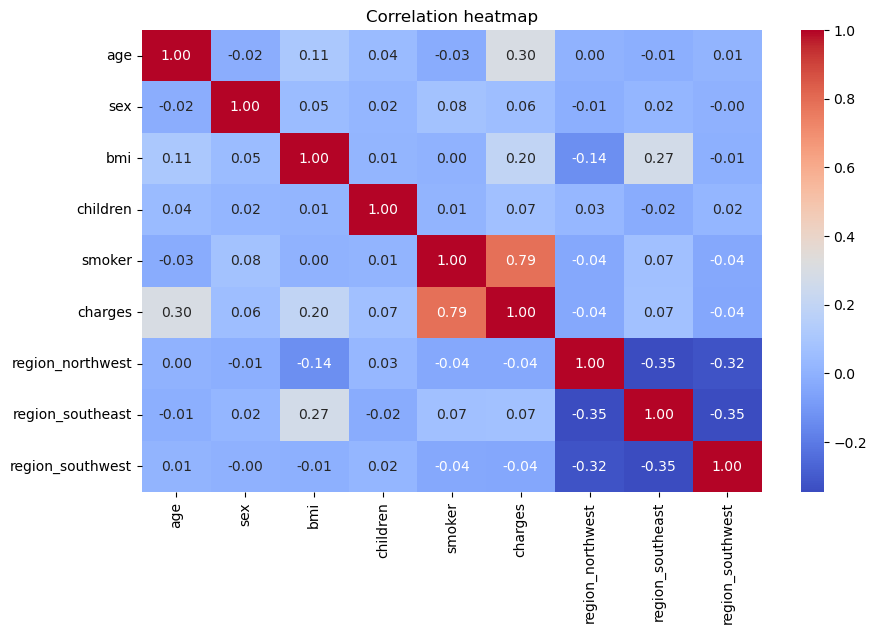

In [50]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap"); plt.show()

# Model Training
## LinearRegression

In [51]:
X = df.drop('charges', axis=1)
y = df['charges']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print(X_train.shape, X_test.shape)

(1069, 8) (268, 8)


In [52]:
model1 = LinearRegression()
model1.fit(X_train, y_train)


LinearRegression()

In [53]:
y_train_pred = model1.predict(X_train)
y_test_pred = model1.predict(X_test)

In [54]:
print("Train R2 :", round(r2_score(y_train, y_train_pred), 4))
print("Test  R2 :", round(r2_score(y_test, y_test_pred), 4))
print("Test MAE :", round(mean_absolute_error(y_test, y_test_pred), 2))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 2))

Train R2 : 0.7489
Test  R2 : 0.753
Test MAE : 4396.03
Test RMSE: 6445.64


In [55]:
pd.DataFrame({'Feature': X.columns, 'Coefficient': model1.coef_.round(2)})

,Feature,Coefficient
0,age,244.21
1,sex,-201.73
2,bmi,311.97
3,children,492.08
4,smoker,23789.59
5,region_northwest,-448.35
6,region_southeast,-993.10
7,region_southwest,-1087.80


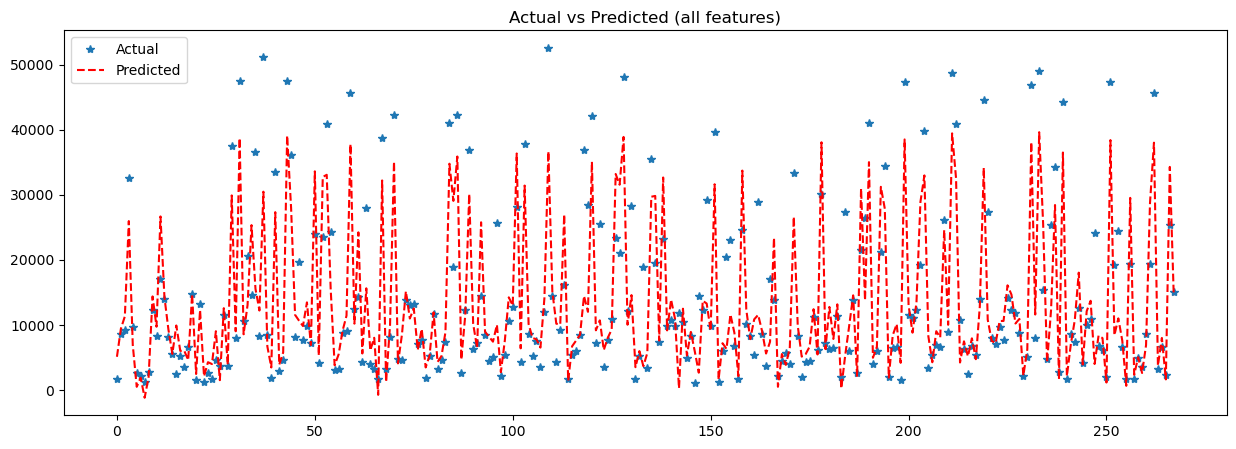

In [56]:
final_df = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_test_pred})
plt.figure(figsize=(15, 5))
obsno = list(range(len(final_df)))
plt.plot(obsno, final_df.Actual, "*", label="Actual")
plt.plot(obsno, final_df.Predicted, "r--", label="Predicted")
plt.legend(); plt.title("Actual vs Predicted (all features)"); plt.show()

# OLS

In [58]:
train_data = X_train.copy(); train_data['charges'] = y_train
test_data  = X_test.copy();  test_data['charges']  = y_test

ols_model = smf.ols("charges ~ age + sex + bmi + children + smoker + region_northwest + region_southeast + region_southwest", data=train_data).fit()
ols_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     395.1
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          9.52e-312
Time:                        12:14:30   Log-Likelihood:                -10808.
No. Observations:                1069   AIC:                         2.163e+04
Df Residuals:                    1060   BIC:                         2.168e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept        -1.071e+04   1107.897     -9.663      0.000   -1.29e+04   -8531.319
age                244.2136     13.059     18.701      0.000     218.589     269.838
sex               -201.7254    366.435     -0.551      0.582    -920.745     517.294
bmi                311.9652     31.628      9.863      0.000     249.904     374.027
children           492.0814    152.398      3.229      0.001     193.045     791.117
smoker            2.379e+04    457.171     52.036      0.000    2.29e+04    2.47e+04
region_northwest  -448.3506    525.734     -0.853      0.394   -1479.949     583.248
region_southeast  -993.1001    530.581     -1.872      0.062   -2034.209      48.009
region_southwest -1087.7975    524.039     -2.076      0.038   -2116.069     -59.526
==============================================================================
Omnibus:                      269.407   Durbin-Watson:                   2.019
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              734.940
Skew:                           1.287   Prob(JB):                    2.57e-160
Kurtosis:                       6.142   Cond. No.                         318.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## dropping sex, which has highest p_val

In [59]:
ols_model1 = smf.ols("charges ~ age + bmi + children + smoker + region_northwest + region_southeast + region_southwest", data=train_data).fit()
ols_model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     451.8
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          5.02e-313
Time:                        12:15:26   Log-Likelihood:                -10808.
No. Observations:                1069   AIC:                         2.163e+04
Df Residuals:                    1061   BIC:                         2.167e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept        -1.079e+04   1097.197     -9.833      0.000   -1.29e+04   -8635.446
age                244.4382     13.048     18.733      0.000     218.834     270.042
bmi                311.2213     31.589      9.852      0.000     249.237     373.206
children           490.3821    152.317      3.219      0.001     191.506     789.258
smoker            2.378e+04    456.632     52.075      0.000    2.29e+04    2.47e+04
region_northwest  -449.6984    525.556     -0.856      0.392   -1480.946     581.549
region_southeast  -991.9507    530.403     -1.870      0.062   -2032.708      48.807
region_southwest -1082.5220    523.779     -2.067      0.039   -2110.283     -54.761
==============================================================================
Omnibus:                      269.527   Durbin-Watson:                   2.017
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              735.649
Skew:                           1.288   Prob(JB):                    1.80e-160
Kurtosis:                       6.144   Cond. No.                         315.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [60]:
ols_model1 = smf.ols("charges ~ age + bmi + children + smoker", data=train_data).fit()
ols_model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.747
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     787.5
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          4.02e-316
Time:                        12:16:26   Log-Likelihood:                -10810.
No. Observations:                1069   AIC:                         2.163e+04
Df Residuals:                    1064   BIC:                         2.166e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.102e+04   1049.464    -10.502      0.000   -1.31e+04   -8961.705
age          245.1792     13.057     18.778      0.000     219.559     270.799
bmi          297.0907     30.323      9.798      0.000     237.591     356.590
children     486.1492    152.327      3.191      0.001     187.253     785.045
smoker      2.377e+04    455.899     52.138      0.000    2.29e+04    2.47e+04
==============================================================================
Omnibus:                      270.801   Durbin-Watson:                   2.015
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              738.048
Skew:                           1.294   Prob(JB):                    5.43e-161
Kurtosis:                       6.141   Cond. No.                         296.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Finally, R2 value is 74%

# VIF for multicollinearity check

In [61]:
def vif_table(frame):
    Xc = sm.add_constant(frame)
    return pd.DataFrame({'Feature': frame.columns, 'VIF': [variance_inflation_factor(Xc.values, i + 1) 
    for i in range(frame.shape[1])]}).sort_values('VIF', ascending=False)

vif_table(X)

,Feature,VIF
6,region_southeast,1.651779
7,region_southwest,1.529044
5,region_northwest,1.517673
2,bmi,1.106742
0,age,1.016794
4,smoker,1.012100
1,sex,1.008944
3,children,1.004017


### All vifs are close to 1, so there is no multicollinearity 

In [67]:
def backward_elimination(train, target, features, sl=0.05):
    features = list(features)
    while True:
        m = smf.ols(f"{target} ~ " + " + ".join(features), data=train).fit()
        pvals = m.pvalues.drop('Intercept')
        worst = pvals.idxmax()
        if pvals[worst] > sl:
            print(f"Dropping {worst:18s} p = {pvals[worst]:.4f}")
            features.remove(worst)
        else:
            return m, features

all_feats = [c for c in train_data.columns if c != 'charges']
best_ols, selected = backward_elimination(train_data, 'charges', all_feats)
print("\nSelected features:", selected)
print("Adj R2:", round(best_ols.rsquared_adj, 4))

Dropping sex                p = 0.5821
Dropping region_northwest   p = 0.3924
Dropping region_southeast   p = 0.0962
Dropping region_southwest   p = 0.1644

Selected features: ['age', 'bmi', 'children', 'smoker']
Adj R2: 0.7466


In [68]:
def evaluate(features):
    m = LinearRegression().fit(X_train[features], y_train)
    return round(r2_score(y_train, m.predict(X_train[features])), 4), round(r2_score(y_test, m.predict(X_test[features])), 4)

feature_sets = {
    "All 8 features"                   : list(X.columns),
    "After p-value elimination"        : selected,
    "age + bmi + smoker"               : ['age', 'bmi', 'smoker'],
    "smoker only"                      : ['smoker'],
    "age + bmi (no smoker)"            : ['age', 'bmi'],
}
rows = []
for name, f in feature_sets.items():
    tr, te = evaluate(f)
    rows.append([name, len(f), tr, te])
comparison = pd.DataFrame(rows, columns=['Model', 'No. of features', 'Train R2', 'Test R2'])
comparison

,Model,No. of features,Train R2,Test R2
0,All 8 features,8,0.7489,0.7530
1,After p-value elimination,4,0.7475,0.7525
2,age + bmi + smoker,3,0.7451,0.7508
3,smoker only,1,0.6269,0.5935
4,age + bmi (no smoker),2,0.0979,0.1675


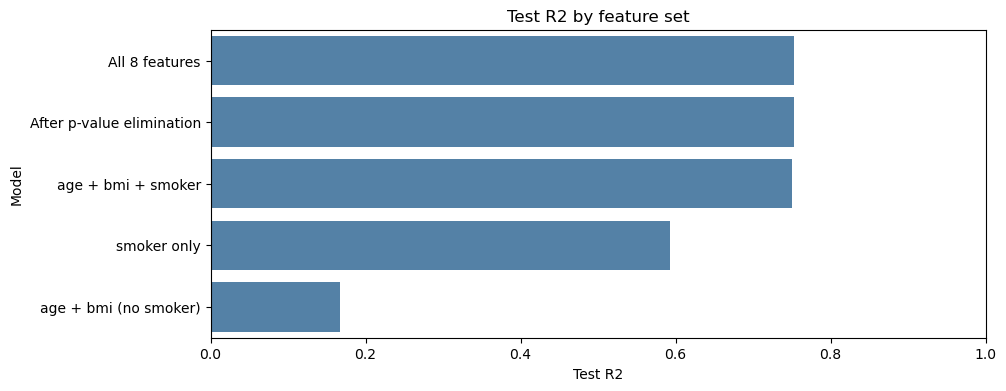

In [69]:
plt.figure(figsize=(10, 4))
sns.barplot(x='Test R2', y='Model', data=comparison, color='steelblue')
plt.title("Test R2 by feature set"); plt.xlim(0, 1); plt.show()

# Conclusion on features:
### the model with 3–4 features (age, bmi, smoker, ±children) scores the same as the model with all 8. `sex` and `region` add nothing, and `smoker` alone explains roughly 60% of the variation.

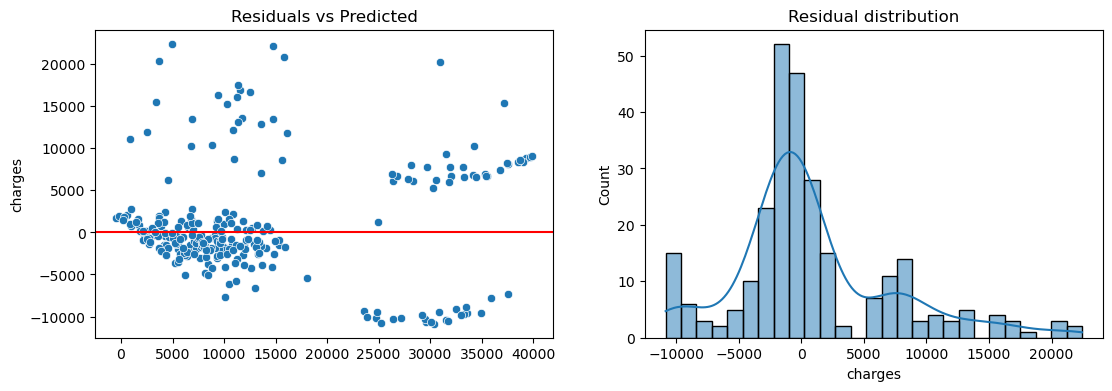

In [70]:
final_model = LinearRegression().fit(X_train[selected], y_train)
pred = final_model.predict(X_test[selected])
residuals = y_test - pred

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(x=pred, y=residuals, ax=ax[0]); ax[0].axhline(0, color='r'); ax[0].set_title("Residuals vs Predicted")
sns.histplot(residuals, kde=True, ax=ax[1]); ax[1].set_title("Residual distribution")
plt.show()

In [71]:
for frame in (X_train, X_test):
    frame['bmi30_smoker'] = ((frame.bmi >= 30) & (frame.smoker == 1)).astype(int)

improved = selected + ['bmi30_smoker']
tr, te = evaluate(improved)
print("Features:", improved)
print("Train R2:", tr, "  Test R2:", te)

Features: ['age', 'bmi', 'children', 'smoker', 'bmi30_smoker']
Train R2: 0.8632   Test R2: 0.8536


In [78]:
model = LinearRegression()
model.fit(X_train[['age', 'bmi', 'children', 'smoker', 'bmi30_smoker']], y_train)

def predict_charges(age, bmi, children, smoker):
    smoker = 1 if smoker == 'yes' else 0
    bmi30_smoker = 1 if (bmi >= 30 and smoker == 1) else 0

    new_data = pd.DataFrame([[age, bmi, children, smoker, bmi30_smoker]],
                            columns=['age', 'bmi', 'children', 'smoker', 'bmi30_smoker'])

    charges = model.predict(new_data)[0]
    print("Estimated yearly insurance charges =", round(charges, 2))

In [79]:
age = int(input("Enter age: "))
bmi = float(input("Enter BMI: "))
children = int(input("Enter number of children: "))
smoker = input("Smoker? (yes/no): ").strip().lower()

predict_charges(age, bmi, children, smoker)

Enter age:  40
Enter BMI:  33
Enter number of children:  2
Smoker? (yes/no):  yes


Estimated yearly insurance charges = 42048.42
